Testing acc 0.7988826815642458
train acc 0.8384831460674157


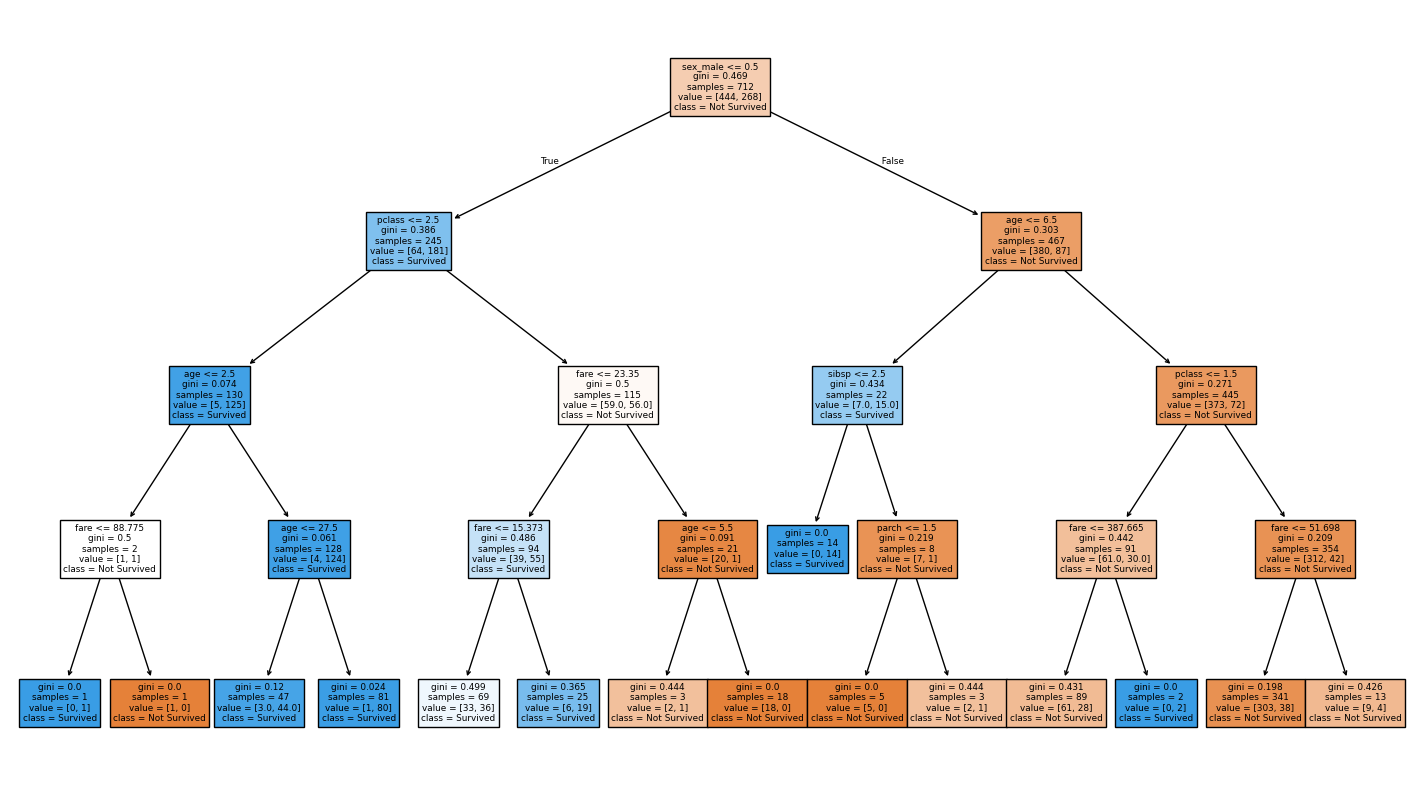

In [23]:

import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Load Titanic dataset
titanic = sns.load_dataset("titanic")

# Select features and target
data = titanic[["pclass", "sex", "age", "sibsp", "parch", "fare", "survived"]].copy()

# Handle missing values
data["age"] = data["age"].fillna(data["age"].median())

# Convert categorical data into numbers
data = pd.get_dummies(data, columns=["sex"], drop_first=True)

# Features and target
X = data.drop("survived", axis=1)
y = data["survived"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train Decision Tree
model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)
y_pred_train=model.predict(X_train)
# Accuracy
print("Testing acc", accuracy_score(y_test, y_pred))
print("train acc", accuracy_score(y_train, y_pred_train))

# Visualize Decision Tree
plt.figure(figsize=(18, 10))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Not Survived", "Survived"],
    filled=True
)
plt.show()


In [28]:
# Rondom forest classfier
from sklearn.ensemble import RandomForestClassifier

rf=RandomForestClassifier(
    n_estimators=601,
    oob_score=True,

)
rf.fit(X_train,y_train)
y_pred=rf.predict(X_test)

print("oob Score",rf.oob_score_ * 100, "%")
print("testing accuracy ",accuracy_score(y_test, y_pred) * 100, "%")

oob Score 80.89887640449437 %
testing accuracy  79.88826815642457 %
